A saturated pixel tells that the true intensity was at the maximum value or above, so the mean intensity of a region with saturated pixels could be underestimated. 

This notebook reports how much each droplet is saturated. No droplet is excluded for subsequent analyses.

  1. saturated fraction per frame of every droplet (and of the spot for bleached droplets)
  2. saturation over time
  4. gallery of the bleached droplets (pre-bleach and first post-bleach frame)
  5. report tables

In the final normalization:

[S(t)/S(pre)] / [T(t)/T(pre)]; S: bleached spot, T: whole bleached droplet

- saturation before the bleach enters only through the ratio T(pre)/S(pre). If spot and whole
  droplet are underestimated by the same factor, it cancels; usually the spot (in the bright core)
  is more saturated than the whole droplet (which includes its dimmer edges), so the curve is
  scaled up -> mobile fraction overestimated, t½ unaffected
- saturation after the bleach (spot or whole droplet) distorts the curve in those frames
  -> t½ and plateau biased

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from matplotlib.colors import ListedColormap
from skimage import measure
 
RED = ListedColormap(["red"])

# 0. Load Data

In [2]:
# Load stacks, labels and the table of droplets from notebook 02

SEG_DIR = Path("results/segmentation")
BLEACH_DIR = Path("results/bleach_detect")
 
files = sorted(Path("data").glob("*.tif"))
stacks, sat_values, droplet_labels, spot_labels, droplets_info = {}, {}, {}, {}, {}
for f in files:
    name = f.stem
    raw = tifffile.imread(f)
    sat_values[name] = np.iinfo(raw.dtype).max            # 255 for 8-bit data
    stacks[name] = raw.astype(np.float64)
    droplet_labels[name] = tifffile.imread(SEG_DIR / f"{name}_droplet_labels.tif")
    spot_labels[name] = tifffile.imread(BLEACH_DIR / f"{name}_spot_labels.tif")
 
    tab = pd.read_csv(BLEACH_DIR / f"{name}_all_droplets.csv")
    tab = tab[~tab["moved"]].copy()                         # moved at the bleach: excluded in notebook 02
    tab["role"] = np.where(tab["bleached"], "bleached", "reference")
    droplets_info[name] = tab[["droplet", "area", "role"]].reset_index(drop=True)
    n_b = (tab["role"] == "bleached").sum()

    print(f"{name}: {raw.shape[0]} frames, "
          f"{n_b} bleached + {len(tab) - n_b} reference droplets, "
          f"saturation at {sat_values[name]}")

Apt2+Ca_2: 21 frames, 16 bleached + 99 reference droplets, saturation at 255
Apt2_1: 21 frames, 9 bleached + 39 reference droplets, saturation at 255
PEG_3: 21 frames, 10 bleached + 32 reference droplets, saturation at 255


# 1. Saturated fraction per frame

For every droplet the fraction of saturated pixels is computed in every frame; for bleached droplets also for the spot.

In [3]:
# Saturated fraction per frame: whole droplet (all droplets) and spot (only bleached droplets)

# sat_frames: a table with rows = droplet IDs, columns = frames, values = fraction of the region's pixels that are saturated in that frame.
# same for spots in sat_frames_spot

# new columns in the droplet_info table:
# the pre-bleach value (sat_droplet_pre), the worst post-bleach value (sat_droplet_post_worst) and the frame of that worst value (sat_droplet_post_worst_frame).
# three analogous columns also for spots (NaN if droplet is reference)

FRAME_PRE = 0
sat_frames = {}        # per file: whole droplets (all droplets)
sat_frames_spot = {}   # per file: spots (only bleached droplets)

for name, tab in droplets_info.items():
    sat_stack = stacks[name] >= sat_values[name]                    # True = saturated
    bleached_ids = tab.loc[tab["role"] == "bleached", "droplet"]

    for region, label_img, ids, store in (("droplet", droplet_labels[name], tab["droplet"], sat_frames),   # iteration over whole droplets
                                          ("spot", spot_labels[name], bleached_ids, sat_frames_spot)):    # iteration over spots
        table = pd.DataFrame.from_dict(
            {d: sat_stack[:, label_img == d].mean(axis=1) for d in ids},   # fraction per frame
            orient="index", columns=range(sat_stack.shape[0]))
        table.columns.name = "frame"
        store[name] = table

        post = table.loc[:, FRAME_PRE + 1:]                          # post-bleach frames only
        worst_post = post.max(axis=1)
        tab[f"sat_{region}_pre"] = tab["droplet"].map(table[FRAME_PRE])
        tab[f"sat_{region}_post_worst"] = tab["droplet"].map(worst_post)
        tab[f"sat_{region}_post_worst_frame"] = tab["droplet"].map(post.idxmax(axis=1).where(worst_post > 0))

In [4]:
# Bleached droplets: spot and whole droplet above REPORT_THRESHOLD
# spot_pre_above / droplet_pre_above: True if above the threshold in the pre-bleach frame (per droplet).
# spot / droplet_post_frames_above: post-bleach frames in which it is above the threshold (per droplet).
# summary: per file, number of bleached droplets above the threshold before / after the bleach.

REPORT_THRESHOLD = 0.75
TH = f"{REPORT_THRESHOLD:.0%}"                       # "75%", used in labels

bleached_report = {}   # per file: table of the bleached droplets
summary_rows = []
for name, tab in droplets_info.items():
    is_bleached = tab["role"] == "bleached"
    tab["spot_pre_above"] = is_bleached & (tab["sat_spot_pre"] > REPORT_THRESHOLD)
    tab["droplet_pre_above"] = is_bleached & (tab["sat_droplet_pre"] > REPORT_THRESHOLD)

    b = tab[is_bleached].copy()
    ids = b["droplet"].values
    row = {"file": name, "bleached": len(b)}
    for region, table in (("droplet", sat_frames[name]),   # iteration over whole droplets
                          ("spot", sat_frames_spot[name])):    # iteration over spots
        above_post = (table.loc[ids] > REPORT_THRESHOLD).loc[:, FRAME_PRE + 1:]    # which droplets (or spots) are above the threshold in which post-bleach frames
        b[f"{region}_post_frames_above"] = [list(r.index[r]) for _, r in above_post.iterrows()]
        row[f"{region}_above_{TH}_before"] = int(b[f"{region}_pre_above"].sum())
        row[f"{region}_above_{TH}_after"] = int(above_post.any(axis=1).sum())    # True for each droplet (ors spot) above the threshold in at least one post-bleach frame
    bleached_report[name] = b
    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)

In [5]:
# Summary for bleached droplets and spots

for _, row in summary.iterrows():
    print(f"{row['file']} ({row['bleached']} bleached droplets): "
          f"{row[f'spot_above_{TH}_before']} spots with saturated fract. >{TH} before the bleach, "
          f"{row[f'spot_above_{TH}_after']} after  | "
          f"{row[f'droplet_above_{TH}_before']} whole droplets with saturated fract. >{TH} before the bleach , "
          f"{row[f'droplet_above_{TH}_after']} after")

Apt2+Ca_2 (16 bleached droplets): 0 spots with saturated fract. >75% before the bleach, 0 after  | 0 whole droplets with saturated fract. >75% before the bleach , 0 after
Apt2_1 (9 bleached droplets): 4 spots with saturated fract. >75% before the bleach, 0 after  | 0 whole droplets with saturated fract. >75% before the bleach , 0 after
PEG_3 (10 bleached droplets): 2 spots with saturated fract. >75% before the bleach, 0 after  | 0 whole droplets with saturated fract. >75% before the bleach , 0 after


In [7]:
# Summary for reference droplets

for name, tab in droplets_info.items():
    r = tab[tab["role"] == "reference"]
    r_sat = r[["sat_droplet_pre", "sat_droplet_post_worst"]].max(axis=1) > 0
    print(f"{name}: {r_sat.sum()} of {len(r)} references with saturated pixels | "
          f"pre-bleach: median {r['sat_droplet_pre'].median():.0%}, max {r['sat_droplet_pre'].max():.0%} | "
          f"post-bleach (worst frame): median {r['sat_droplet_post_worst'].median():.0%}, "
          f"max {r['sat_droplet_post_worst'].max():.0%}")

Apt2+Ca_2: 71 of 99 references with saturated pixels | pre-bleach: median 0%, max 7% | post-bleach (worst frame): median 10%, max 45%
Apt2_1: 38 of 39 references with saturated pixels | pre-bleach: median 44%, max 73% | post-bleach (worst frame): median 47%, max 80%
PEG_3: 19 of 32 references with saturated pixels | pre-bleach: median 1%, max 57% | post-bleach (worst frame): median 9%, max 73%


# 2. Saturation over time

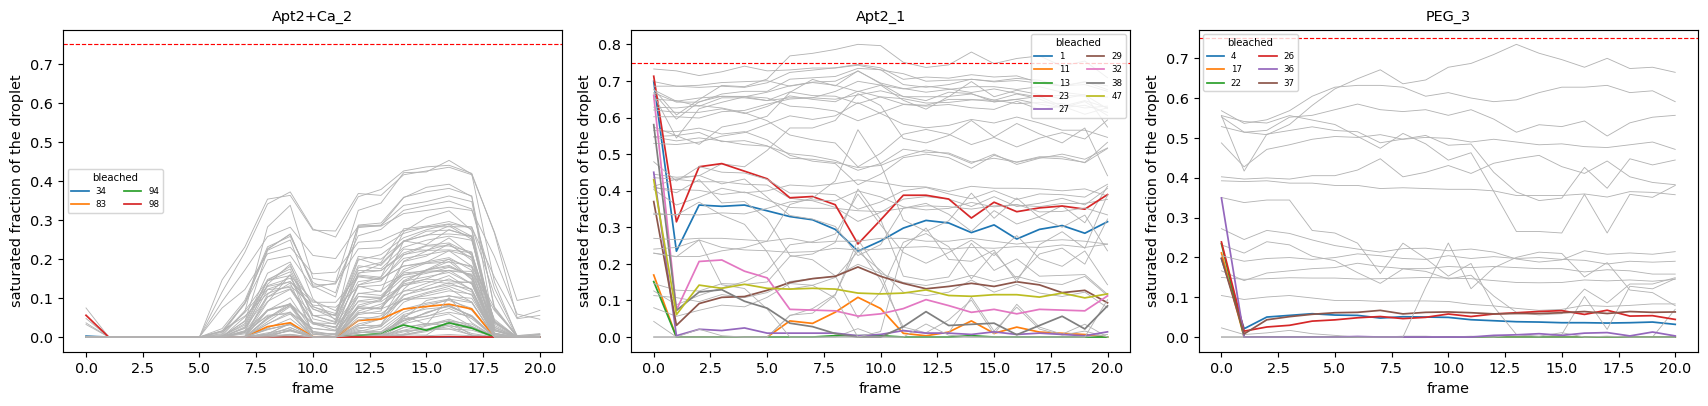

In [8]:
# Saturated fraction of each droplet over time (coloured: bleached, legend = droplet ID; gray: references)

MAX_SAT_FRAC = 0.75

fig, axes = plt.subplots(1, len(sat_frames), squeeze=False, figsize=(5.5 * len(sat_frames), 4))

for ax, (name, sf) in zip(axes[0], sat_frames.items()):
    roles = droplets_info[name].set_index("droplet")["role"]
    for d, row in sf.iterrows():
        if row.max() == 0:                        # never saturated: not drawn
            continue
        if roles[d] == "bleached":
            ax.plot(row.index, row.values, "-", lw=1.2, label=str(d))
        else:
            ax.plot(row.index, row.values, "-", lw=0.6, color="0.7")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("frame")
    ax.set_ylabel("saturated fraction of the droplet")
    ax.axhline(MAX_SAT_FRAC, color="red", ls="--", lw=0.8)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(title="bleached", fontsize=6, title_fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

# 3. Gallery of the bleached droplets

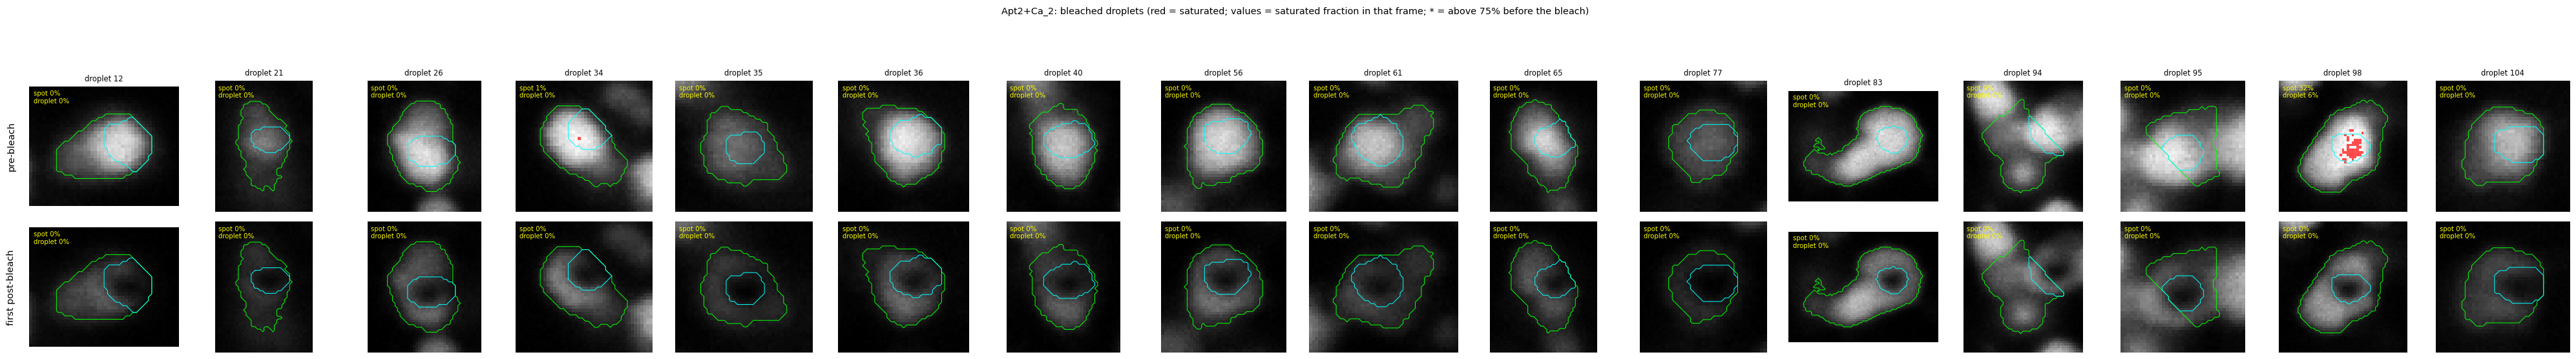

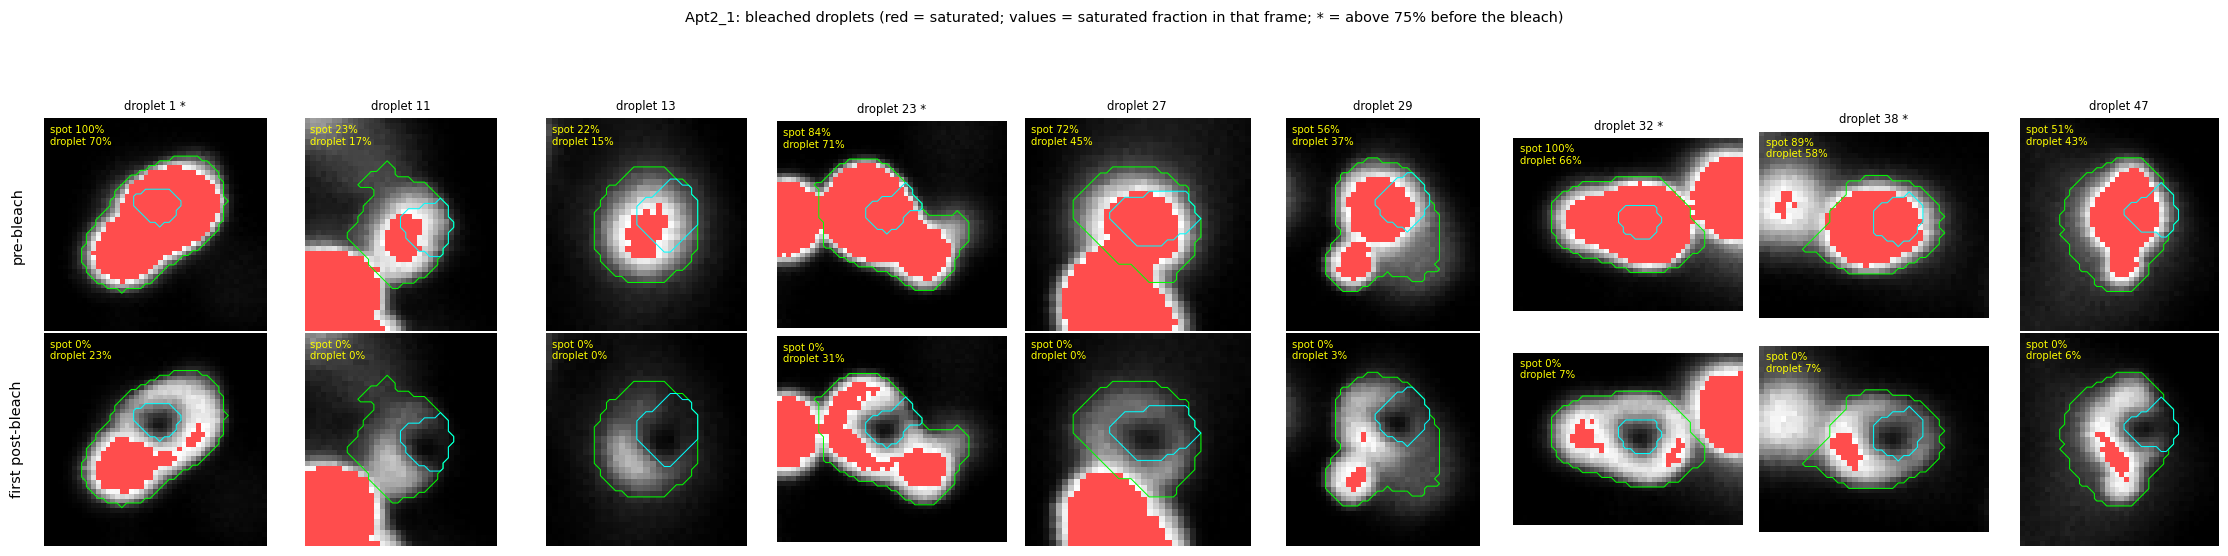

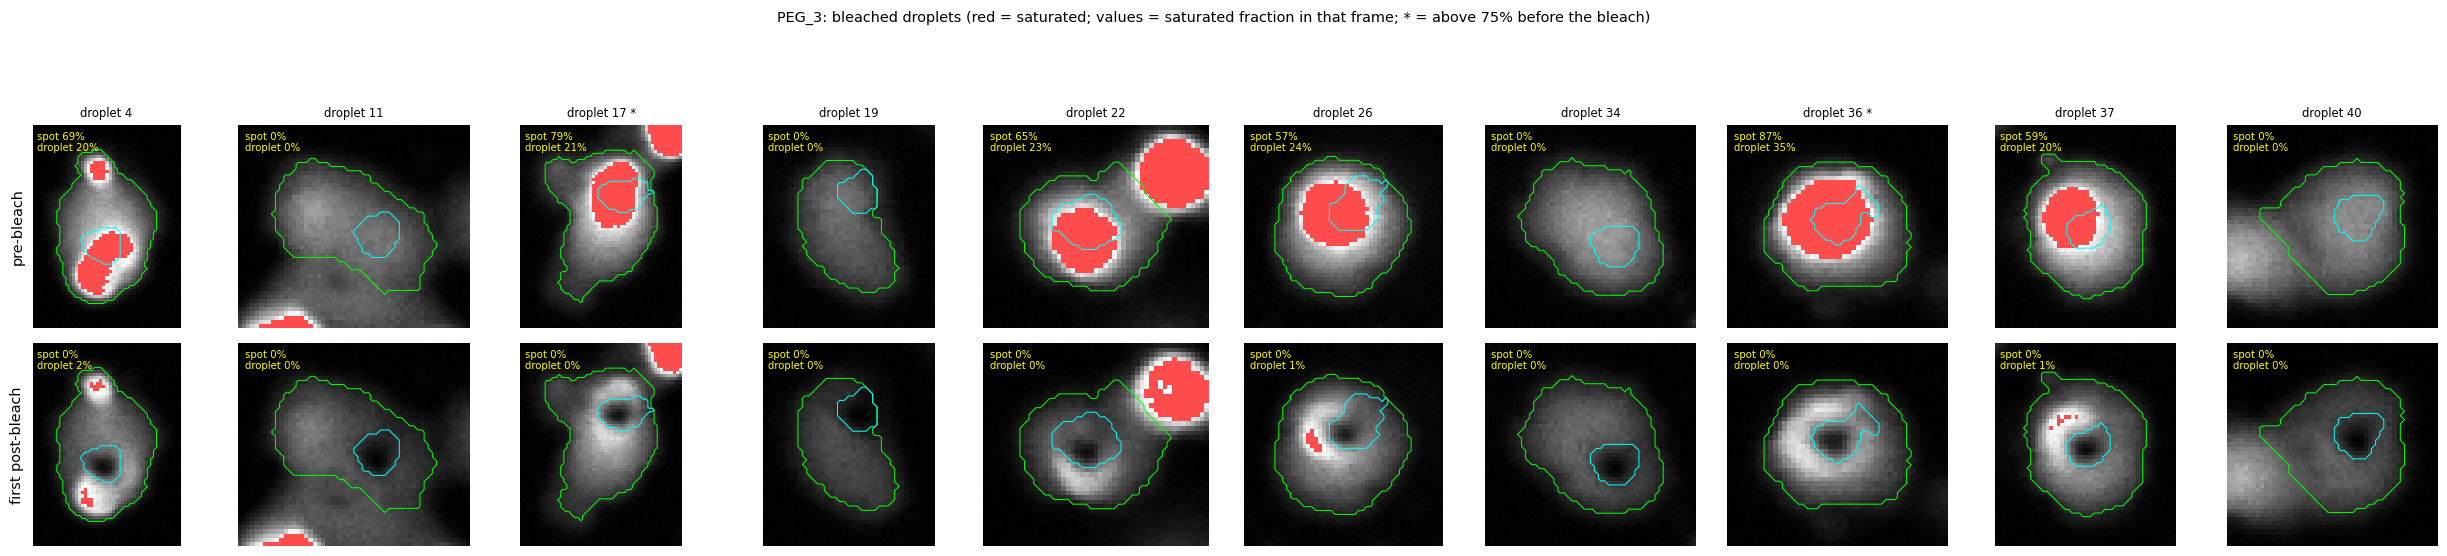

In [9]:
# Pre-bleach frame (top) and first post-bleach frame (bottom); red = saturated pixels
# The values written in each panel are the saturated fractions of spot and whole droplet in that frame. 
# The "worst" post-bleach values are instead in the report table.
# "*" = above REPORT_THRESHOLD before the bleach (spot or whole droplet).

PAD = 8
 
for name, tab in droplets_info.items():
    sub = tab[tab["role"] == "bleached"]
    if sub.empty:
        continue
    labels, spots, stack = droplet_labels[name], spot_labels[name], stacks[name]
    sat_stack = stack >= sat_values[name]
    sfd, sfs = sat_frames[name], sat_frames_spot[name]
    first_post = FRAME_PRE + 1
 
    fig, axes = plt.subplots(2, len(sub), squeeze=False, figsize=(2.4 * len(sub), 5.4))
    for j, (_, row) in enumerate(sub.iterrows()):
        d = row["droplet"]
        r0, c0, r1, c1 = measure.regionprops((labels == d).astype(int))[0].bbox
        sl = (slice(max(r0 - PAD, 0), r1 + PAD), slice(max(c0 - PAD, 0), c1 + PAD))
        for i, t in enumerate((FRAME_PRE, first_post)):
            saturated = sat_stack[t][sl]
            ax = axes[i, j]
            ax.imshow(stack[t][sl], cmap="gray", vmin=0, vmax=sat_values[name])
            if saturated.any():
                ax.imshow(np.ma.masked_where(~saturated, saturated), cmap=RED, alpha=0.7,
                          interpolation="nearest")
            ax.contour((labels[sl] == d).astype(float), levels=[0.5], colors="lime", linewidths=0.7)
            ax.contour((spots[sl] == d).astype(float), levels=[0.5], colors="cyan", linewidths=0.7)
            ax.text(0.03, 0.97, f"spot {sfs.loc[d, t]:.0%}\ndroplet {sfd.loc[d, t]:.0%}",
                    transform=ax.transAxes, color="yellow", fontsize=7, va="top")
            ax.axis("off")
        mark = " *" if (row["droplet_pre_above"] or row["spot_pre_above"]) else ""
        axes[0, j].set_title(f"droplet {d}{mark}", fontsize=8)
    axes[0, 0].text(-0.15, 0.5, "pre-bleach", transform=axes[0, 0].transAxes, rotation=90, va="center")
    axes[1, 0].text(-0.15, 0.5, "first post-bleach", transform=axes[1, 0].transAxes, rotation=90,
                    va="center")
    fig.suptitle(f"{name}: bleached droplets (red = saturated; values = saturated fraction in that frame; "
                 f"* = above {REPORT_THRESHOLD:.0%} before the bleach)", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.6 / fig.get_figheight()))
    plt.show()

# 5. Save the report

In [10]:
REPORT_DIR = Path("results/saturation_report")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

for name, tab in droplets_info.items():
    tab.to_csv(REPORT_DIR / f"{name}_saturation.csv", index=False)
    sat_frames[name].to_csv(REPORT_DIR / f"{name}_saturation_per_frame.csv", index_label="droplet")
summary.to_csv(REPORT_DIR / "saturation_summary.csv", index=False)

with open(REPORT_DIR / "saturation_parameters.json", "w") as fh:
    json.dump({"frame_pre": FRAME_PRE, "saturation_values": sat_values,
               "report_threshold": REPORT_THRESHOLD}, fh, indent=2, default=int)
print("saved to", REPORT_DIR)

saved to results/saturation_report
